1. Считавание датасета из файла train.csv

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


2. Визуализация распределения значений признаков Survived, Pclass, Age, Sex, Parch

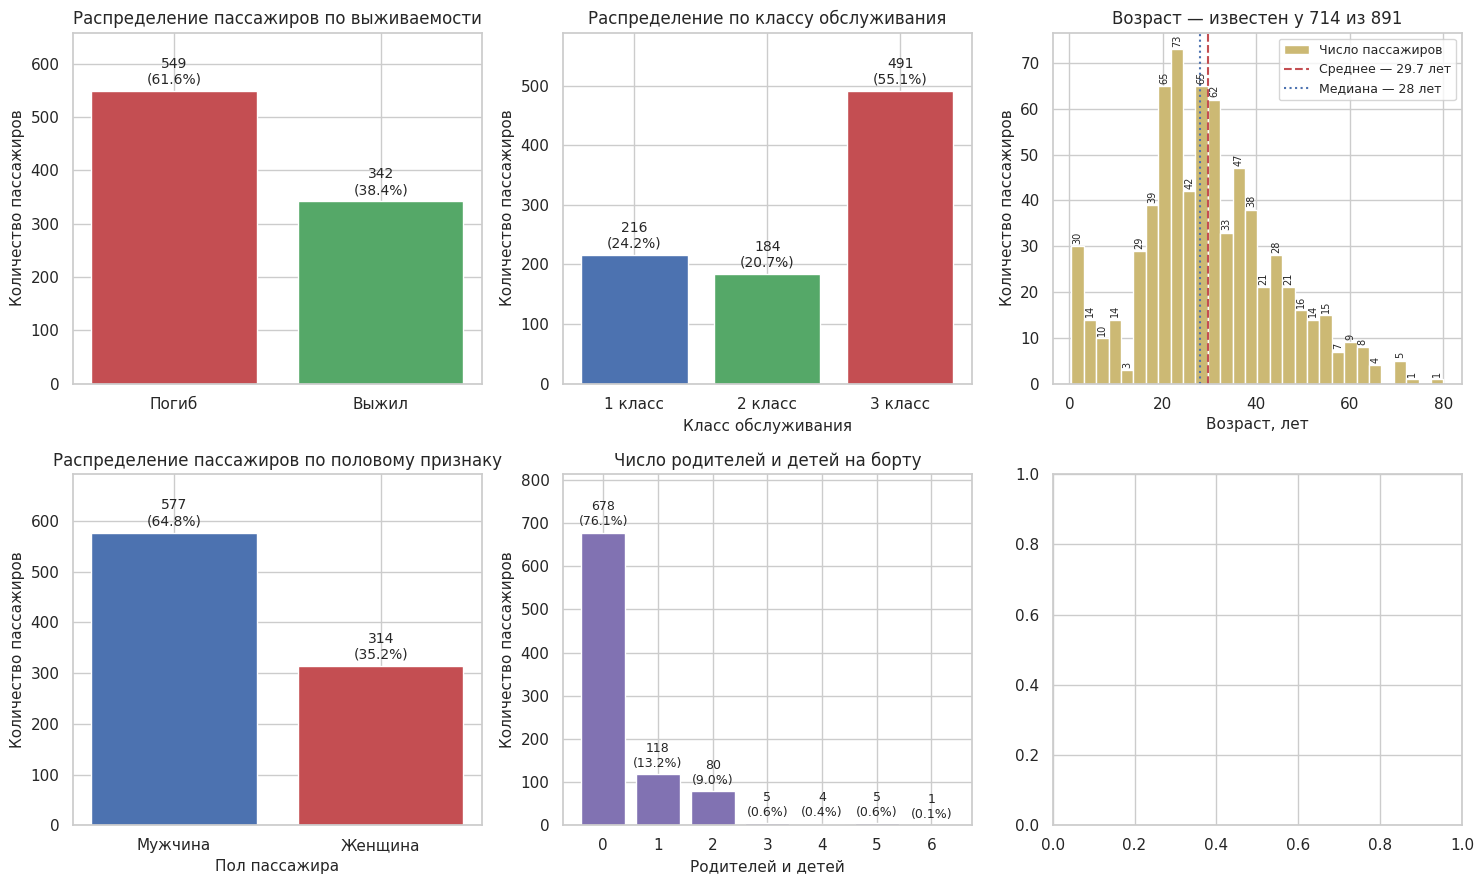

In [99]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

# Распределение пассажиров на погибших и выживших
counts = df['Survived'].value_counts().sort_index()
total = counts.sum()
labels = {0: 'Погиб', 1: 'Выжил'}
names = [labels[i] for i in counts.index]

bars = axes[0].bar(names, counts.values, color=['#C44E52', '#55A868'])
texts = [f"{v}\n({v / total * 100:.1f}%)" for v in counts.values]
axes[0].bar_label(bars, labels=texts, padding=3, fontsize=10)
axes[0].set_title('Распределение пассажиров по выживаемости', fontsize=12)
axes[0].set_ylabel('Количество пассажиров', fontsize=11)
axes[0].set_ylim(0, counts.max() * 1.20)

# Распределение пассажиров по классам
counts = df['Pclass'].value_counts().sort_index()
total = counts.sum()
labels = {1: '1 класс', 2: '2 класс', 3: '3 класс'}
names = [labels[i] for i in counts.index]

bars = axes[1].bar(names, counts.values, color=['#4C72B0', '#55A868', '#C44E52'])
texts = [f"{v}\n({v / total * 100:.1f}%)" for v in counts.values]
axes[1].bar_label(bars, labels=texts, padding=3, fontsize=10)
axes[1].set_title('Распределение по классу обслуживания', fontsize=12)
axes[1].set_xlabel('Класс обслуживания', fontsize=11)
axes[1].set_ylabel('Количество пассажиров', fontsize=11)
axes[1].set_ylim(0, counts.max() * 1.20)

# Распределение пассажиров по возрасту
ax = axes[2]
age = df['Age'].dropna()
counts, bins, patches = ax.hist(
    age, bins=30, color="#CCB974", edgecolor="white", label="Число пассажиров"
)

# Среднее и медиана вертикальными линиями
ax.axvline(age.mean(), color="#C44E52", linestyle="--",
           label=f"Среднее — {age.mean():.1f} лет")
ax.axvline(age.median(), color="#4C72B0", linestyle=":",
           label=f"Медиана — {age.median():.0f} лет")

# Подписи значений над каждым столбцом
for count, patch in zip(counts, patches):
    if count > 0:
        ax.text(patch.get_x() + patch.get_width() / 2,
                count + 0.5, int(count),
                ha='center', va='bottom', fontsize=7, rotation=90)

ax.set_title(f'Возраст — известен у {age.size} из {len(df)}', fontsize=12)
ax.set_xlabel('Возраст, лет', fontsize=11)
ax.set_ylabel('Количество пассажиров', fontsize=11)
ax.legend(fontsize=9)

# Распределение пассажиров по полу
counts = df['Sex'].value_counts()
total = counts.sum()
labels = {'male': 'Мужчина', 'female': 'Женщина'}
names = [labels[i] for i in counts.index]

bars = axes[3].bar(names, counts.values, color=['#4C72B0', '#C44E52'])
texts = [f"{v}\n({v / total * 100:.1f}%)" for v in counts.values]
axes[3].bar_label(bars, labels=texts, padding=3, fontsize=10)
axes[3].set_title('Распределение пассажиров по половому признаку', fontsize=12)
axes[3].set_xlabel('Пол пассажира', fontsize=11)
axes[3].set_ylabel('Количество пассажиров', fontsize=11)
axes[3].set_ylim(0, counts.max() * 1.20)

# Число родителей и детей на борту
counts = df['Parch'].value_counts().sort_index()
total = counts.sum()

names = [str(i) for i in counts.index]

bars = axes[4].bar(names, counts.values, color="#8172B2")
texts = [f"{v}\n({v / total * 100:.1f}%)" for v in counts.values]
axes[4].bar_label(bars, labels=texts, padding=3, fontsize=9)
axes[4].set_title('Число родителей и детей на борту', fontsize=12)
axes[4].set_xlabel('Родителей и детей', fontsize=11)
axes[4].set_ylabel('Количество пассажиров', fontsize=11)
axes[4].set_ylim(0, counts.max() * 1.20)

plt.tight_layout()
plt.show()

3. График типа boxplot для столбца Age

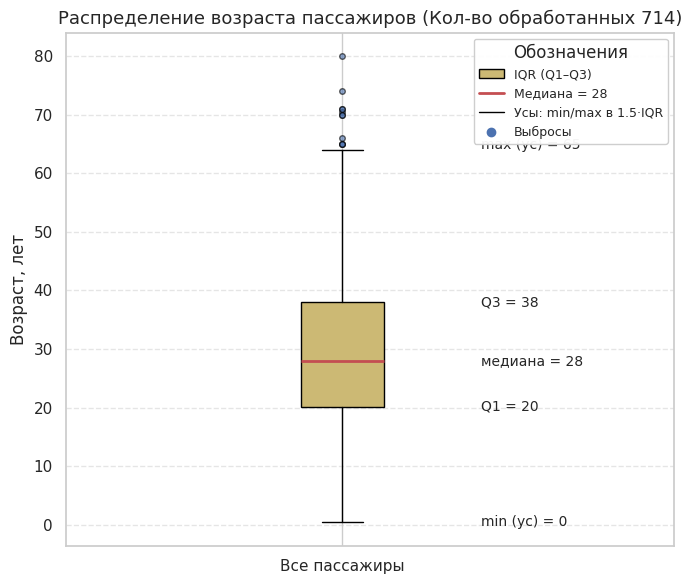

In [87]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

df = pd.read_csv('train.csv')
age = df['Age'].dropna()
q1, med, q3 = age.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
lower = max(age.min(), q1 - 1.5 * iqr)
upper = min(age.max(), q3 + 1.5 * iqr)

fig, ax = plt.subplots(figsize=(7, 6))
ax.boxplot(age, vert=True, patch_artist=True,
           boxprops=dict(facecolor='#CCB974'),
           medianprops=dict(color='#C44E52', linewidth=2),
           flierprops=dict(marker='o', markerfacecolor='#4C72B0',
                           markersize=4, alpha=0.6))

for value, label in [
    (lower, f'min (ус) = {lower:.0f}'),
    (q1,    f'Q1 = {q1:.0f}'),
    (med,   f'медиана = {med:.0f}'),
    (q3,    f'Q3 = {q3:.0f}'),
    (upper, f'max (ус) = {upper:.0f}'),
]:
    ax.text(1.25, value, label, va='center', fontsize=10)

legend_elements = [
    Patch(facecolor='#CCB974', edgecolor='black', label='IQR (Q1–Q3)'),
    Line2D([0], [0], color='#C44E52', lw=2, label=f'Медиана = {med:.0f}'),
    Line2D([0], [0], color='black', lw=1, label='Усы: min/max в 1.5·IQR'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#4C72B0',
           markeredgecolor='#4C72B0', markersize=6, label='Выбросы'),
]
ax.legend(handles=legend_elements, loc='upper right',
          fontsize=9, framealpha=0.95, title='Обозначения')

ax.set_title(f'Распределение возраста пассажиров (Кол-во обработанных {age.size})', fontsize=13)
ax.set_ylabel('Возраст, лет', fontsize=12)
ax.set_xticks([1]); ax.set_xticklabels(['Все пассажиры'])
ax.set_xlim(0.5, 1.6)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Согласно полученному графику медиана равна 28 годам, половина пассажиров Титаника моложе данного возраста. В выборку попали не все пассажиры корабля, по 177 информация отсутсвует. Выбросы связаны с уже очень пожилыми людьми на борту корабля, нижняя граница обусловлена присутствием на корабле младенцев. Q1=20, Q3=30

График типа pie chart для переменных Survived, Pclass

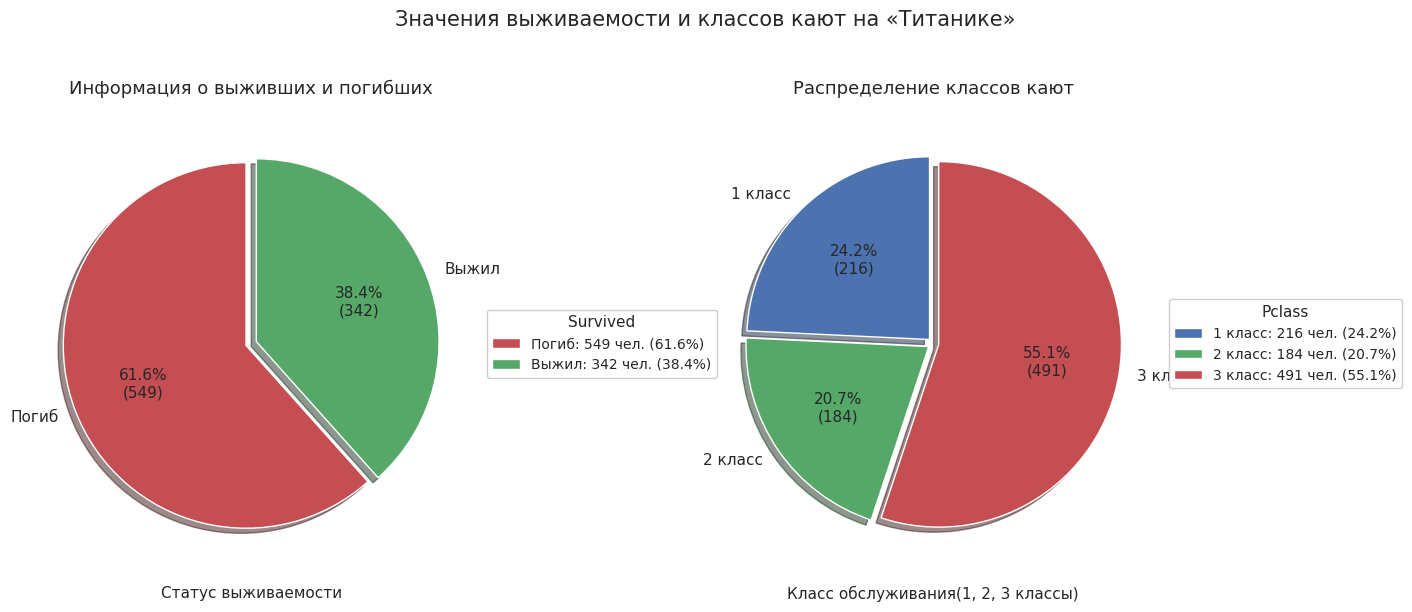

In [90]:
import pandas as pd
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Распределение количества пассажиров на выживших и погибших
counts = df['Survived'].value_counts().sort_index()
total = counts.sum()
labels = {0: 'Погиб', 1: 'Выжил'}
names = [labels[i] for i in counts.index]
colors = ['#C44E52', '#55A868']

def autopct_with_count(p):
    return f"{p:.1f}%\n({round(p * total / 100)})"

wedges, texts, autotexts = axes[0].pie(
    counts.values,
    labels=names,
    autopct=autopct_with_count,
    startangle=90,
    colors=colors,
    explode=[0.03, 0.03],
    shadow=True,
    textprops={'fontsize': 11},
)


axes[0].set_title('Информация о выживших и погибших',
                  fontsize=13, pad=15)

axes[0].set_xlabel('Статус выживаемости',
                   fontsize=11, labelpad=10)

axes[0].legend(
    wedges,
    [f"{name}: {cnt} чел. ({cnt / total * 100:.1f}%)"
     for name, cnt in zip(names, counts.values)],
    title='Survived',
    loc='center left',
    bbox_to_anchor=(1.0, 0.5),
    fontsize=10,
    title_fontsize=11,
    framealpha=0.95,
)

# ---------- Pclass ----------
counts = df['Pclass'].value_counts().sort_index()
total = counts.sum()
labels = {1: '1 класс', 2: '2 класс', 3: '3 класс'}
names = [labels[i] for i in counts.index]
colors = ['#4C72B0', '#55A868', '#C44E52']

wedges, texts, autotexts = axes[1].pie(
    counts.values,
    labels=names,
    autopct=autopct_with_count,
    startangle=90,
    colors=colors,
    explode=[0.03, 0.03, 0.03],
    shadow=True,
    textprops={'fontsize': 11},
)

axes[1].set_title('Распределение классов кают',
                  fontsize=13, pad=15)
axes[1].set_xlabel('Класс обслуживания(1, 2, 3 классы)',
                   fontsize=11, labelpad=10)

axes[1].legend(
    wedges,
    [f"{name}: {cnt} чел. ({cnt / total * 100:.1f}%)"
     for name, cnt in zip(names, counts.values)],
    title='Pclass',
    loc='center left',
    bbox_to_anchor=(1.0, 0.5),
    fontsize=10,
    title_fontsize=11,
    framealpha=0.95,
)

fig.suptitle('Значения выживаемости и классов кают на «Титанике»',
             fontsize=15, y=1.02)

fig.tight_layout()
plt.show()

График типа pairplot для всех числовых переменных датасета

Числовые признаки: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


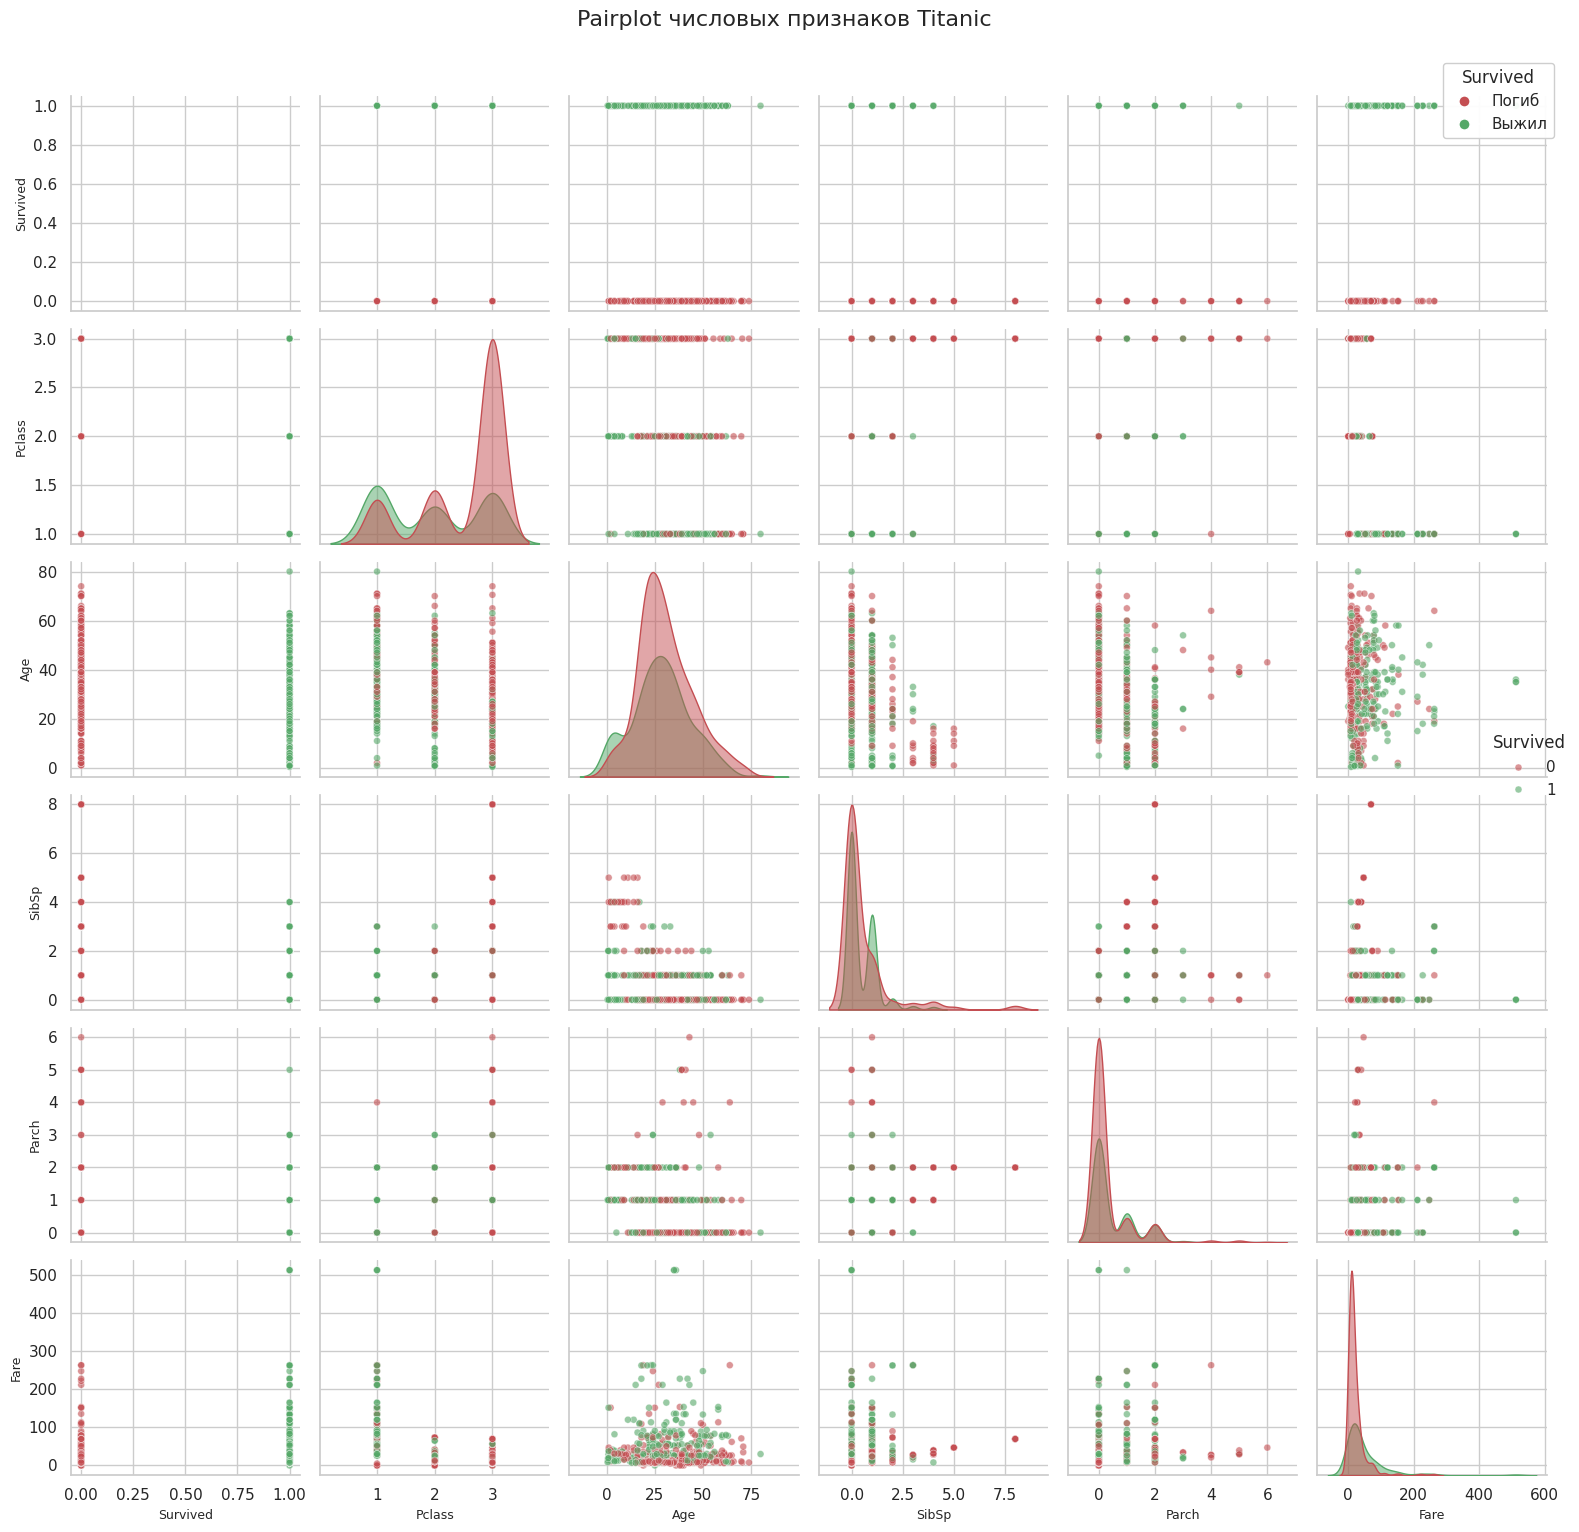

In [93]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Числовые признаки
numeric_cols = df.select_dtypes(include='number').columns.tolist()
print("Числовые признаки:", numeric_cols)
# ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


plot_cols = [c for c in numeric_cols if c != 'PassengerId']

sns.set_theme(style="whitegrid")

g = sns.pairplot(
    df,
    vars=plot_cols,
    hue='Survived',
    palette={0: '#C44E52', 1: '#55A868'},
    diag_kind='kde',
    plot_kws=dict(alpha=0.6, s=25, edgecolor='white'),
    diag_kws=dict(fill=True, alpha=0.5),
    corner=False,
)

g.fig.suptitle(
    'Pairplot числовых признаков Titanic',
    fontsize=16, y=1.02
)


for ax in g.axes.flatten():
    if ax is not None:
        ax.set_xlabel(ax.get_xlabel(), fontsize=9)
        ax.set_ylabel(ax.get_ylabel(), fontsize=9)


handles = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#C44E52', markersize=8, label='Погиб'),
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='#55A868', markersize=8, label='Выжил'),
]
g.fig.legend(
    handles=handles,
    title='Survived',
    loc='upper right',
    bbox_to_anchor=(0.99, 0.99),
    fontsize=11,
    title_fontsize=12,
    framealpha=0.95,
)

plt.tight_layout()
plt.show()

Интерактивный sunburst plot

In [97]:
import pandas as pd
import plotly.express as px

df = pd.read_csv('train.csv')

# Подписи для уровней
df['Pclass_label'] = df['Pclass'].map({
    1: '1 класс',
    2: '2 класс',
    3: '3 класс',
})
df['Sex_label'] = df['Sex'].map({
    'male': 'Мужчины',
    'female': 'Женщины',
})

fig = px.sunburst(
    df,
    path=['Pclass_label', 'Sex_label'],
    title='Распределение пассажиров по классу и половому признаку',
    color='Pclass_label',
    color_discrete_map={
        '1 класс': '#4C72B0',
        '2 класс': '#55A868',
        '3 класс': '#C44E52',
    },
    hover_data={'Pclass_label': True, 'Sex_label': True},
)

fig.update_traces(
    textinfo='label+value+percent parent',
    insidetextorientation='radial',
)

fig.update_layout(
    title=dict(
        text='Распределение пассажиров по классу и половому признаку',
        x=0.5,
        xanchor='center',
        font=dict(size=18),
    ),
    legend=dict(
        title='Класс каюты',
        orientation='h',
        yanchor='bottom',
        y=-0.1,
        xanchor='center',
        x=0.5,
        font=dict(size=12),
        title_font=dict(size=13),
    ),


)

fig.show()